# QFF 2026 Phase 1: PS-O1 Max-Cut with QAOA on Processor A vs Processor B

Run this notebook top to bottom (Kernel > Restart & Run All). It reproduces every table and figure in `results/`.

**Assumptions (provisional):**
- Processor A and B coupling graphs were built from the organizer deck (slide 4 diagrams) and checked against the Processor A/B Configuration document.
- Noise values and basis gates are **not official** (the organizers said they will be fixed after Phase 1 shortlisting). They are our documented assumptions in `processors/*.json`; results use 2-qubit error 0.005 and 0.01.
- Main benchmark: the full 6-vertex problem (6 qubits). Processor A has 5 qubits and cannot host it.
- Supplementary study: our own 5-variable reduction (fixing one vertex). It is **not organizer-approved** and is reported separately.

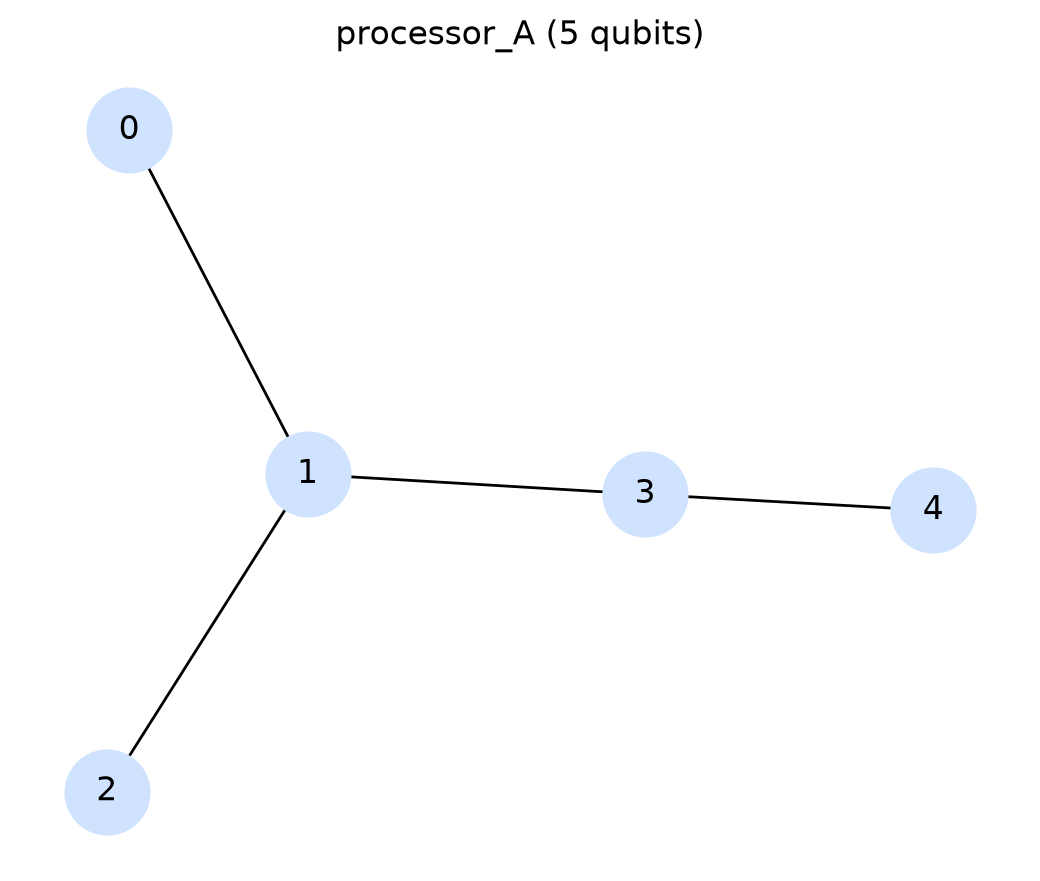

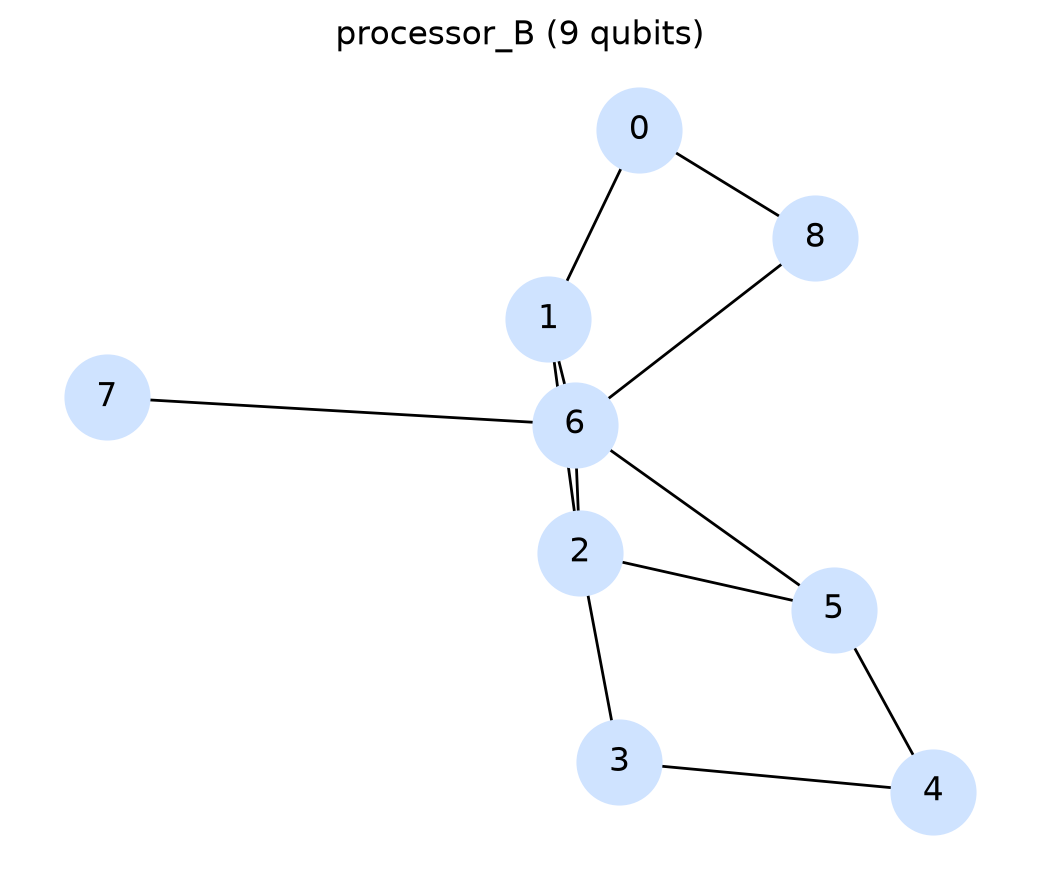

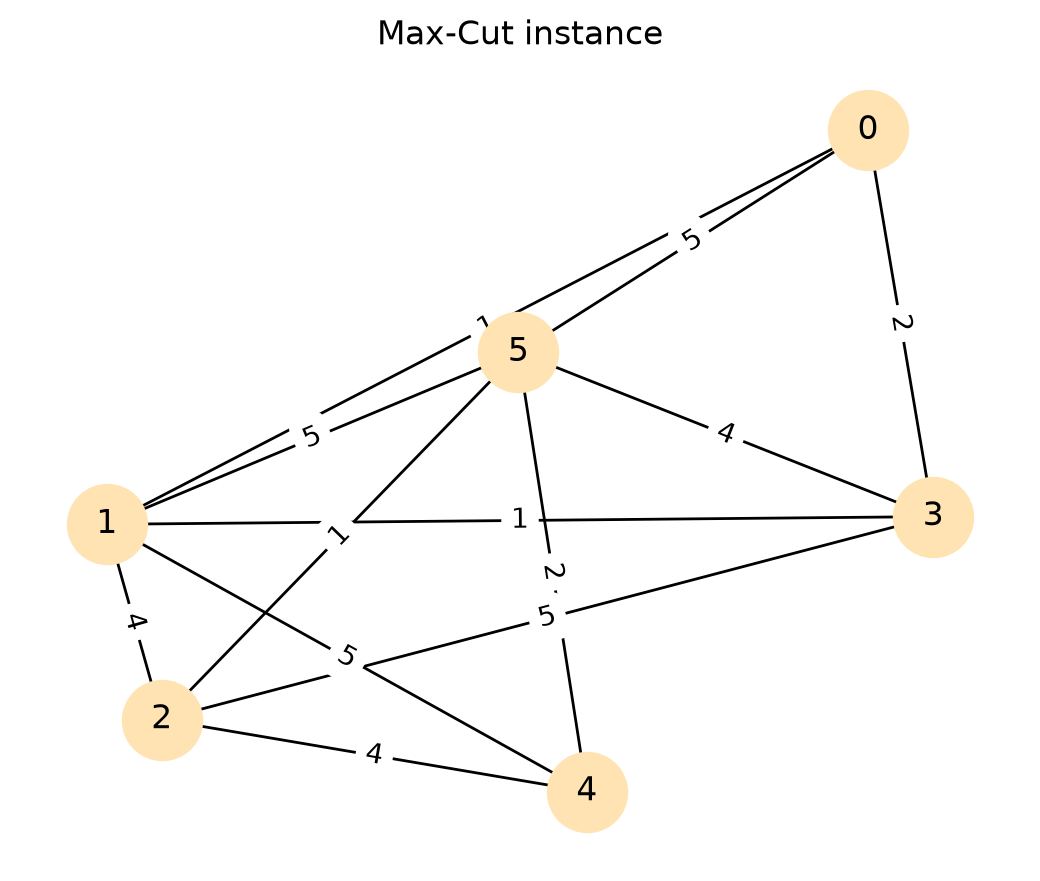

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))

from IPython.display import Image, display
from src.processors import load_processor
from src.problem import make_graph
from src.visualization import plot_coupling_map, plot_weighted_graph

procA = load_processor("processors/processor_A.json")
procB = load_processor("processors/processor_B.json")
plot_coupling_map(procA, "results/figures/processor_A_graph.png")
plot_coupling_map(procB, "results/figures/processor_B_graph.png")

N = 6
edges = make_graph(N, seed=42)
plot_weighted_graph(edges, N, "results/figures/problem_graph.png")

# save the instance so the run is reproducible
Path("data/raw").mkdir(parents=True, exist_ok=True)
with open("data/raw/instance_seed42.txt", "w") as f:
    f.write("# i j w\n")
    for i, j, w in edges:
        f.write(f"{i} {j} {w}\n")

for p in ["processor_A_graph", "processor_B_graph", "problem_graph"]:
    display(Image(f"results/figures/{p}.png"))

## 1. Processors built from the organizer diagrams

The coupling graphs were transcribed by hand from slide 4 of the organizer deck and then compared with `processors/*.json`.
The diagram has no qubit numbers, so nodes are named by position; we check that the two graphs are the same up to relabeling.
The slide labels Processor B "7 qubits", but the drawing has 9 nodes and the organizers confirmed 9.

In [2]:
import networkx as nx

# Processor A: top hub with left and right leaves, plus a chain top - mid - bottom.
A_slide = [("top", "left"), ("top", "right"), ("top", "mid"), ("mid", "bottom")]

# Processor B: nodes named N1..N9 by position (N5 = center hub with 5 links, N9 = bottom leaf).
B_slide = [("N3", "N1"), ("N1", "N4"), ("N1", "N5"), ("N4", "N2"), ("N4", "N5"), ("N4", "N8"),
           ("N2", "N6"), ("N3", "N7"), ("N7", "N5"), ("N5", "N8"), ("N8", "N6"), ("N5", "N9")]

for name, slide in [("A", A_slide), ("B", B_slide)]:
    proc = load_processor(f"processors/processor_{name}.json")
    g_json = nx.Graph([tuple(e) for e in proc["coupling_map"]])
    g_slide = nx.Graph(slide)
    print(f"Processor {name}: {g_json.number_of_nodes()} qubits, {g_json.number_of_edges()} edges | "
          f"matches slide diagram: {nx.is_isomorphic(g_json, g_slide)}")

Processor A: 5 qubits, 4 edges | matches slide diagram: True
Processor B: 9 qubits, 12 edges | matches slide diagram: True


## 2. Classical baseline and the (supplementary) 5-variable reduction

Brute force over all 2^6 = 64 bitstrings gives the optimum cut. A random assignment cuts half of the total edge weight on average.
The reduction fixes one vertex to side 0 (valid because flipping every vertex keeps the cut value); it is used only for the supplementary study on Processor A.

In [3]:
import pandas as pd
from src.problem import load_edges, brute_force_optimum, reduce_fix_vertex, brute_force_reduced

N = 6
all_edges = load_edges("data/raw/instance_seed42.txt")
optimum, optimum_bits = brute_force_optimum(all_edges, N)
total_weight = sum(w for _, _, w in all_edges)
print("edges:", len(all_edges), "| total weight:", total_weight)
print("classical optimum cut:", optimum, "| optimal bitstrings:", optimum_bits)
print("random-guess baseline (expected cut):", total_weight / 2)

FIXED_VERTEX = 4
red_edges, linear, kept = reduce_fix_vertex(all_edges, N, fixed=FIXED_VERTEX)
opt_r, _ = brute_force_reduced(red_edges, linear, N - 1)
print("\nreduced problem (vertex", FIXED_VERTEX, "fixed):", len(red_edges), "two-qubit edges, linear terms", linear)
print("reduced optimum:", opt_r, "| matches full optimum:", opt_r == optimum)

edges: 12 | total weight: 39
classical optimum cut: 29 | optimal bitstrings: ['001001', '110110']
random-guess baseline (expected cut): 19.5

reduced problem (vertex 4 fixed): 9 two-qubit edges, linear terms {0: 0, 1: 5, 2: 4, 3: 0, 4: 2}
reduced optimum: 29 | matches full optimum: True


In [4]:
import itertools

import numpy as np
import pandas as pd
from src.problem import load_edges, maxcut_qubo, cut_value

N = 6
all_edges = load_edges("data/raw/instance_seed42.txt")
Q = maxcut_qubo(all_edges, N)
print("QUBO matrix Q (x^T Q x = -cut):")
print(pd.DataFrame(Q).astype(int).to_string())

energies = {}
for combo in itertools.product("01", repeat=N):
    bits = "".join(combo)
    x = np.array([int(b) for b in bits])
    e = x @ Q @ x
    assert abs(e + cut_value(all_edges, bits)) < 1e-9, bits
    energies[bits] = e
best_bits = min(energies, key=energies.get)
print("QUBO check passed on 64/64 bitstrings")
print("min x^T Q x =", energies[best_bits], "-> max cut", -energies[best_bits])

QUBO matrix Q (x^T Q x = -cut):
   0   1   2   3   4   5
0 -8   1   0   2   0   5
1  1 -16   4   1   5   5
2  0   4 -14   5   4   1
3  2   1   5 -12   0   4
4  0   5   4   0 -11   2
5  5   5   1   4   2 -17
QUBO check passed on 64/64 bitstrings
min x^T Q x = -29.0 -> max cut 29.0


## 3. QAOA circuit sanity test

At beta = 0 the cost layer only adds phases, so the phase of each basis state must equal 2 * gamma * (cut value difference).
This checks the signs and angle scale of the circuit for both the full and the reduced problem.

In [5]:
import numpy as np
from qiskit.quantum_info import Statevector
from src.problem import reduced_cut_value, key_to_bits
from src.qaoa_circuit import build_qaoa_circuit

g = 0.05
for name, e, lin, n in [("full", all_edges, {}, 6), ("reduced", red_edges, linear, 5)]:
    amps = Statevector(build_qaoa_circuit(g, 0.0, e, lin, n)).to_dict()
    zero = "0" * n
    ref = amps[zero]
    for key, a in amps.items():
        bits = key_to_bits(key)
        dcut = reduced_cut_value(e, lin, bits) - reduced_cut_value(e, lin, zero)
        assert abs(np.angle(np.exp(1j * (np.angle(a / ref) - 2 * g * dcut)))) < 1e-9, (name, key)
    print("circuit test passed:", name)

circuit test passed: full
circuit test passed: reduced


## 4. Optimize the QAOA parameters (p = 1, COBYLA, 10 random restarts)

`src/optimizer.py` maximizes the expected cut with an exact statevector simulation and saves the best angles to `results/tables/best_params.json`.
Angles are periodic and symmetric, so we report the expected cut rather than interpreting gamma and beta.

In [6]:
import json
import subprocess

def run_module(module):
    r = subprocess.run([sys.executable, "-m", module], capture_output=True, text=True)
    print(r.stdout)
    if r.returncode != 0:
        print(r.stderr)
        raise RuntimeError(f"{module} failed")

run_module("src.optimizer")
best_params = json.loads(Path("results/tables/best_params.json").read_text())
best_params

FULL (6 qubits): expected cut 24.784, ratio 0.855, gamma=-0.066, beta=1.890
REDUCED (5 qubits): expected cut 24.546, ratio 0.846, gamma=3.208, beta=5.925
              mean     min     max  ratio_of_max
problem                                         
full_6q     22.789  19.987  24.784         0.855
reduced_5q  21.317  19.500  24.546         0.846
random baseline: 19.5 | optimum: 29



{'optimum': 29,
 'random_baseline': 19.5,
 'full': {'gamma': -0.06589906314648465,
  'beta': 1.8902548762164348,
  'expected_cut': 24.784417370123325,
  'ratio': 0.8546350817283905},
 'reduced': {'fixed_vertex': 4,
  'kept': [0, 1, 2, 3, 5],
  'gamma': 3.2075978634352924,
  'beta': 5.925014660737977,
  'expected_cut': 24.545769665839483,
  'ratio': 0.8464058505461891}}

## 5. Transpilation study: routing cost on A vs B (20 seeds)

Same circuit, same `optimization_level`, 20 transpiler seeds per processor. `swap` stays in the basis so routing SWAPs are visible;
`effective_cx = cx + 3 * swap`. The full 6-qubit circuit cannot be transpiled for Processor A (5 qubits); the error is saved as evidence.

In [7]:
run_module("src.transpile_study")

transpile_df = pd.read_csv("results/tables/transpile_summary.csv")
cols = ["depth", "cx", "swap", "effective_cx", "qubits_used"]
display(transpile_df.groupby(["problem", "processor"])[cols].agg(["mean", "std"]).round(2))

print(Path("results/tables/feasibility_notes.txt").read_text())

                       depth          cx  ... effective_cx qubits_used     
                        mean   std  mean  ...          std        mean  std
problem    processor                      ...                              
full_6q    processor_B  45.5  7.47  24.0  ...         1.41         6.0  0.0
reduced_5q processor_A  43.4  5.51  18.0  ...         0.00         5.0  0.0
           processor_B  35.2  4.91  18.0  ...         1.54         5.0  0.0

[3 rows x 10 columns]
full_6q on processor_A: cannot be transpiled (CircuitTooWideForTarget: 'Number of qubits (6) in circuit-46 is greater than maximum (5) in the coupling_map')



depth          cx      swap       effective_cx        \
                        mean   std  mean  std mean   std         mean   std   
problem    processor                                                          
full_6q    processor_B  45.5  7.47  24.0  0.0  2.3  0.47         30.9  1.41   
reduced_5q processor_A  43.4  5.51  18.0  0.0  4.0  0.00         30.0  0.00   
           processor_B  35.2  4.91  18.0  0.0  1.5  0.51         22.5  1.54   

                       qubits_used       
                              mean  std  
problem    processor                     
full_6q    processor_B         6.0  0.0  
reduced_5q processor_A         5.0  0.0  
           processor_B         5.0  0.0

full_6q on processor_A: cannot be transpiled (CircuitTooWideForTarget: 'Number of qubits (6) in circuit-46 is greater than maximum (5) in the coupling_map')


## 6. Solution quality: ideal reference vs noisy runs

Ideal rows use an exact statevector (topology independent). Noisy rows use the provisional noise model with two-qubit error 0.005 and 0.01
(neither is official), 8192 shots, 5 transpiler seeds. Reported: expected cut / optimum and the probability of the optimal bitstring (bitstring and its complement).

In [8]:
run_module("src.noisy_simulation")

quality_df = pd.read_csv("results/tables/quality_summary.csv")
display(quality_df.round(3))

      problem   case             processor  two_qubit_error  expected_cut  expected_cut_std  ratio  p_optimal  p_optimal_std  best_sampled_cut                      status best_sampled_bits
0     full_6q  ideal  topology-independent            0.000        24.784             0.000  0.855      0.098          0.000               NaN                          ok               NaN
1     full_6q  noisy           processor_A              NaN           NaN               NaN    NaN        NaN            NaN               NaN  cannot_host (6 qubits > 5)               NaN
2     full_6q  noisy           processor_B            0.005        24.124             0.056  0.832      0.089          0.003              29.0                          ok            001001
3     full_6q  noisy           processor_B            0.010        23.835             0.070  0.822      0.084          0.003              29.0                          ok            001001
4  reduced_5q  ideal  topology-independent            0

,problem,case,processor,two_qubit_error,expected_cut,expected_cut_std,ratio,p_optimal,p_optimal_std,best_sampled_cut,status,best_sampled_bits
0,full_6q,ideal,topology-independent,0.000,24.784,0.000,0.855,0.098,0.000,NaN,ok,NaN
1,full_6q,noisy,processor_A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,cannot_host (6 qubits > 5),NaN
2,full_6q,noisy,processor_B,0.005,24.124,0.056,0.832,0.089,0.003,29.0,ok,1001.0
3,full_6q,noisy,processor_B,0.010,23.835,0.070,0.822,0.084,0.003,29.0,ok,1001.0
4,reduced_5q,ideal,topology-independent,0.000,24.546,0.000,0.846,0.089,0.000,NaN,ok,NaN
5,reduced_5q,noisy,processor_A,0.005,23.913,0.047,0.825,0.083,0.003,29.0,ok,101.0
6,reduced_5q,noisy,processor_A,0.010,23.601,0.062,0.814,0.079,0.003,29.0,ok,101.0
7,reduced_5q,noisy,processor_B,0.005,24.007,0.035,0.828,0.084,0.002,29.0,ok,101.0
8,reduced_5q,noisy,processor_B,0.010,23.790,0.048,0.820,0.081,0.002,29.0,ok,101.0


In [9]:
run_module("src.native5_study")
display(pd.read_csv("results/tables/native5_quality_summary.csv").round(3))

edges: [(0, 1, 1), (0, 3, 2), (1, 2, 5), (1, 3, 4), (1, 4, 1), (2, 3, 5), (2, 4, 5), (3, 4, 5)] | total weight: 28
optimum cut: 21 | optimal bitstrings: ['00110', '11001'] | random baseline: 14.0
ideal expected cut 17.526, ratio 0.835
             depth          cx       ... effective_cx       qubits_used      
              mean   std  mean  std  ...         mean   std        mean   std
processor                            ...                                     
processor_A  43.25  4.25  16.0  0.0  ...        25.00  0.00         5.0  0.00
processor_B  34.45  3.85  16.0  0.0  ...        20.35  1.53         5.1  0.31

[2 rows x 10 columns]
    case             processor  two_qubit_error  expected_cut  expected_cut_std  ratio  p_optimal  p_optimal_std
0  ideal  topology-independent            0.000        17.526             0.000  0.835      0.166          0.000
1  noisy           processor_A            0.005        17.100             0.025  0.814      0.149          0.003
2  noisy     

,case,processor,two_qubit_error,expected_cut,expected_cut_std,ratio,p_optimal,p_optimal_std
0,ideal,topology-independent,0.000,17.526,0.000,0.835,0.166,0.000
1,noisy,processor_A,0.005,17.100,0.025,0.814,0.149,0.003
2,noisy,processor_A,0.010,16.911,0.023,0.805,0.142,0.002
3,noisy,processor_B,0.005,17.147,0.019,0.817,0.153,0.003
4,noisy,processor_B,0.010,17.008,0.020,0.810,0.149,0.002


## 7. Figures

figures saved: ['AB_architecture_metrics.png', 'AB_performance.png', 'architecture_tradeoffs.png', 'logical_vs_transpiled.png', 'problem_graph.png', 'processor_A_graph.png', 'processor_B_graph.png', 'restarts.png']



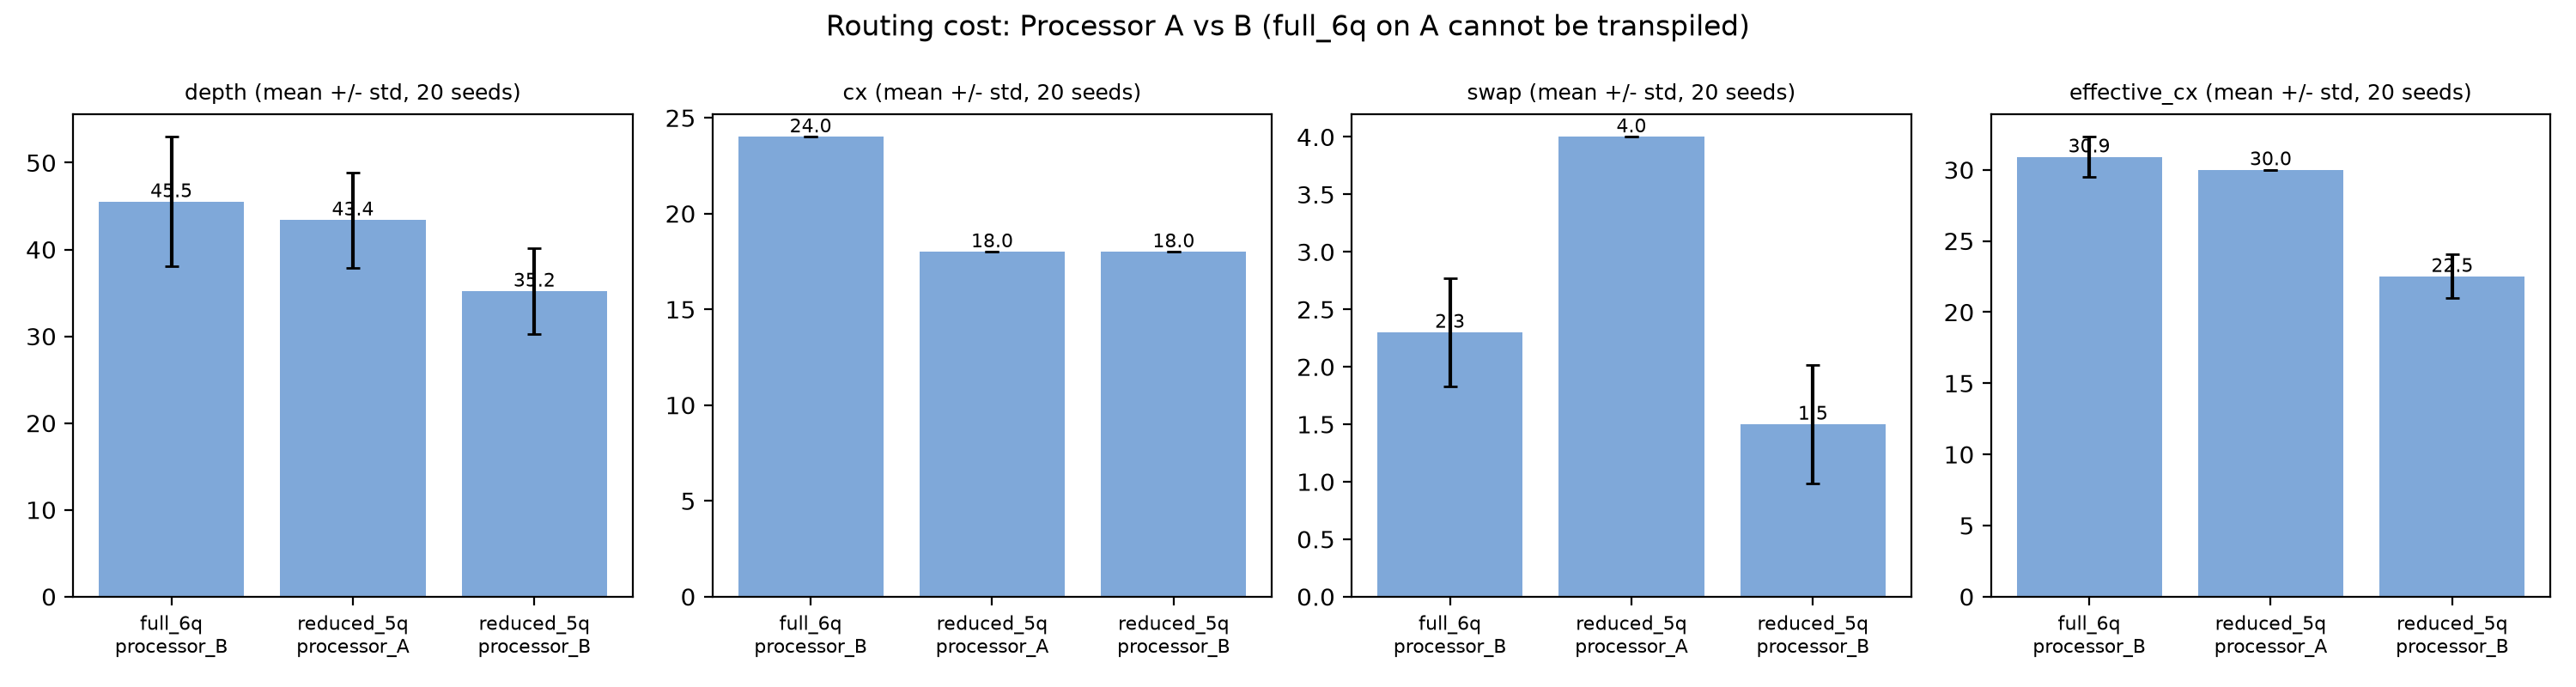

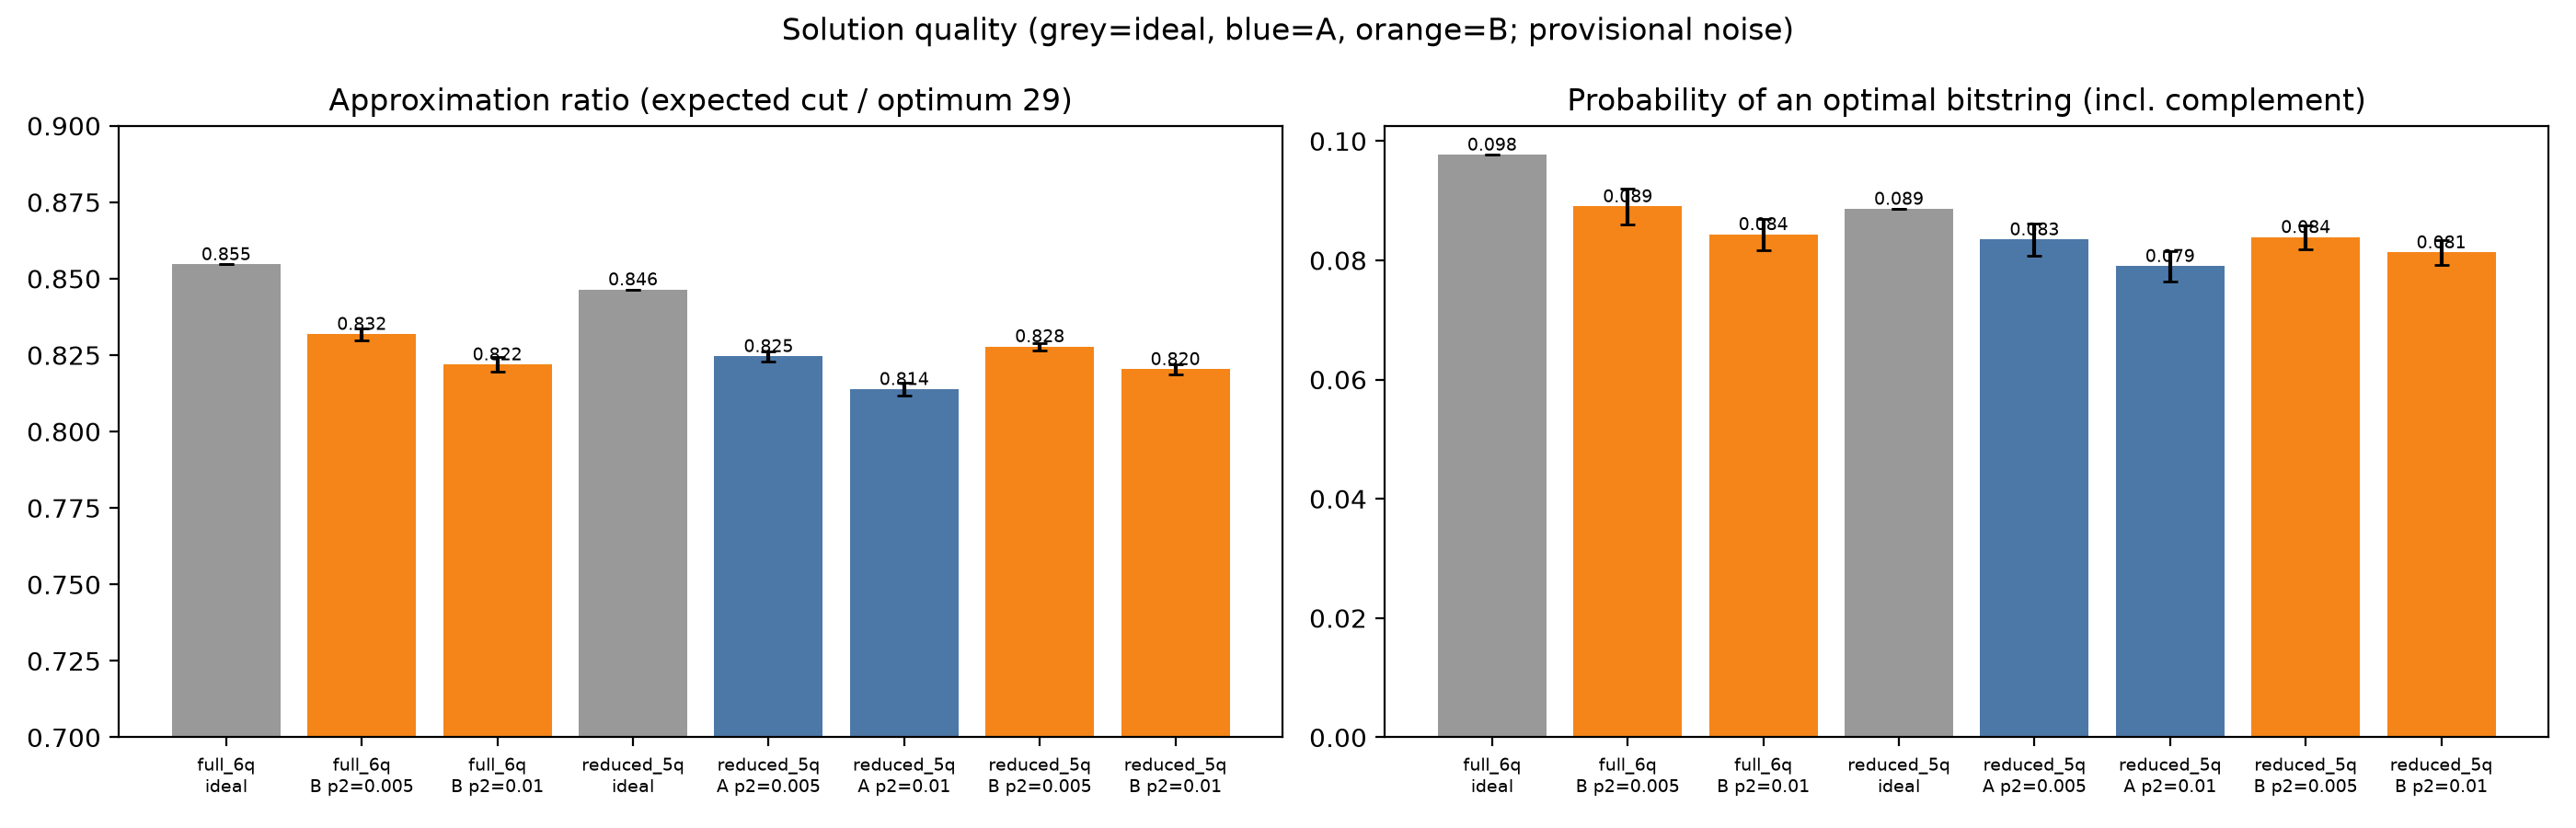

In [10]:
if Path("src/make_figures.py").exists():
    run_module("src.make_figures")
    for p in ["AB_architecture_metrics", "AB_performance"]:
        display(Image(f"results/figures/{p}.png"))
else:
    print("src/make_figures.py not found, skipping figures")

saved tables: ['AB_comparison.csv', 'final_comparison.csv', 'native5_quality_summary.csv', 'native5_restarts.csv', 'native5_transpile_summary.csv', 'processor_A_metrics.csv', 'processor_B_metrics.csv', 'quality_summary.csv', 'restarts.csv', 'restarts_summary.csv', 'transpile_summary.csv']
saved figures: ['AB_architecture_metrics.png', 'AB_performance.png', 'architecture_tradeoffs.png', 'logical_vs_transpiled.png', 'problem_graph.png', 'processor_A_graph.png', 'processor_B_graph.png', 'restarts.png']
saved circuits: ['full_6q_logical.txt', 'full_6q_processor_B_seed0.txt', 'native_5q_logical.txt', 'native_5q_processor_A_seed0.txt', 'native_5q_processor_B_seed0.txt']



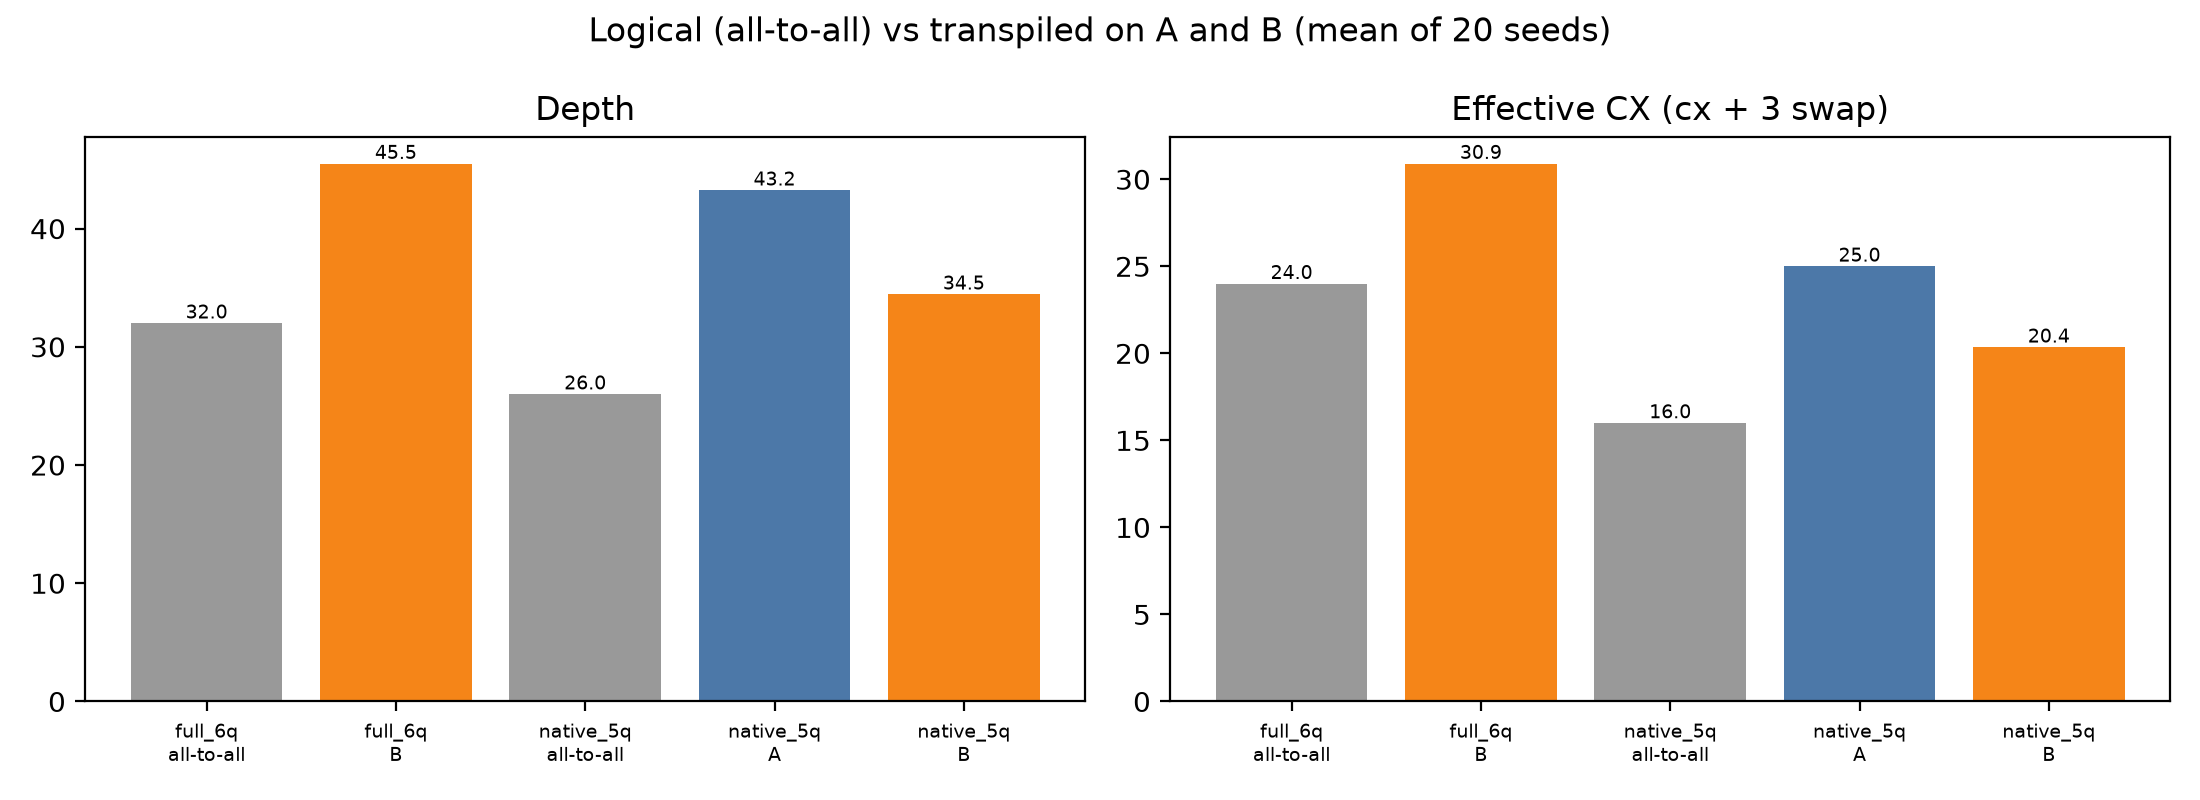

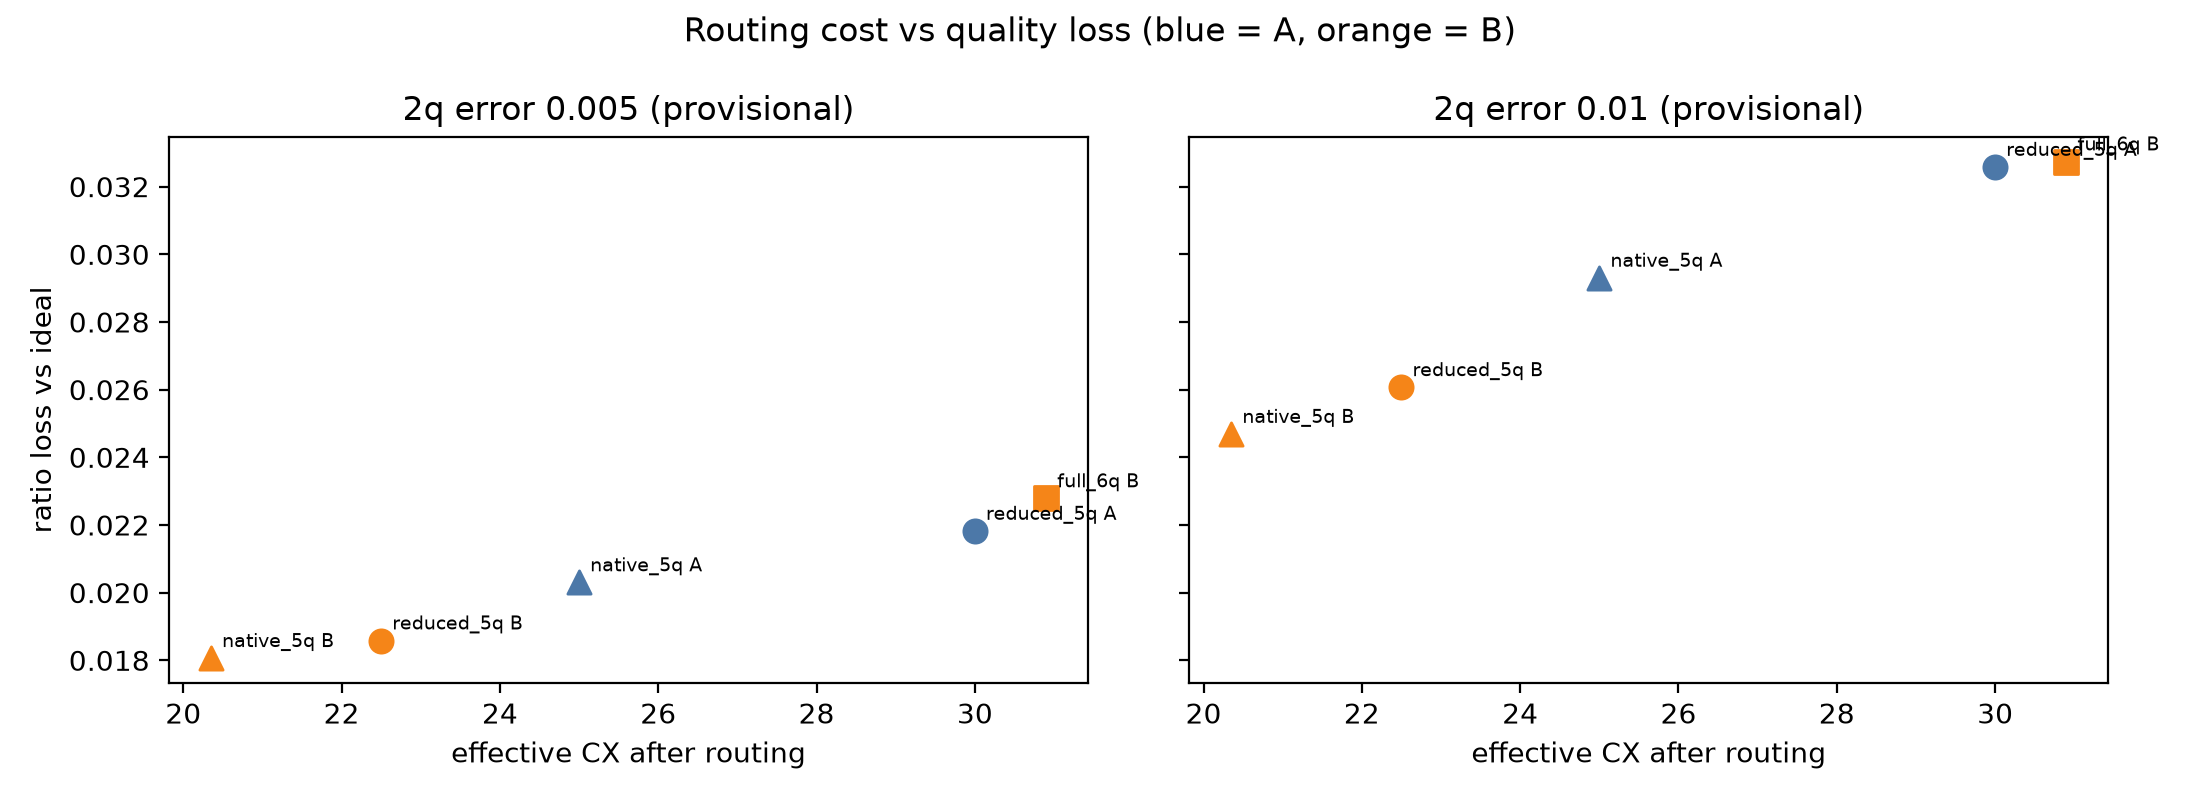

In [11]:
run_module("src.make_extra_outputs")
for p in ["logical_vs_transpiled", "architecture_tradeoffs"]:
    display(Image(f"results/figures/{p}.png"))

## 8. Interpretation

Write the A-vs-B interpretation in `report.md` (what changed, which architectural property explains it, extra operations from routing,
effect on solution quality, noise vs gate-set confounds, limitations). Use only the numbers produced above.